# Fase 2: suelo y sensores
Una temporada muestra el balance hídrico latente junto a las lecturas ruidosas y las acciones de comportamiento.

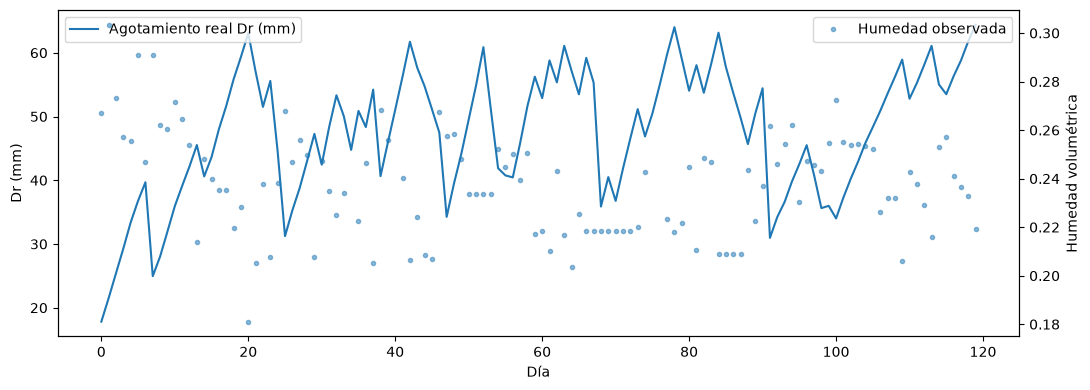

In [1]:
# Resolver la ruta del paquete para esta fase aislada.
from pathlib import Path
import sys
import matplotlib.pyplot as plt
ROOT = Path.cwd()
if not (ROOT / 'src').exists(): ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from src.simulator import simulate

# Simular observaciones y guardar verdad solo para diagnóstico.
observed, truth, weather = simulate(seed=7, regime='dry', return_truth=True)
zone = observed.zona_id == 0
# Graficar agotamiento real y lectura ruidosa del sensor.
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(observed.loc[zone, 't'], truth.loc[zone, 'Dr'], label='Agotamiento real Dr (mm)')
ax2 = ax.twinx()
ax2.plot(observed.loc[zone, 't'], observed.loc[zone, 'theta_obs'], '.', alpha=.5, label='Humedad observada')
ax.set(xlabel='Día', ylabel='Dr (mm)'); ax2.set_ylabel('Humedad volumétrica')
ax.legend(loc='upper left'); ax2.legend(loc='upper right'); plt.tight_layout()